# Medical Insurance Cost Prediction with Regression (Python, scikit-learn)
**Practice notebook — Rishabh Aryan.** Written after the IIT Ropar guest lectures in the IIT Ropar & NIELIT Ropar 6-Month AI/ML programme.

Goal: predict annual medical charges from age, sex, BMI, children, smoking status and region using the **Medical Cost Personal** dataset, compare linear and tree-based regressors, and analyse what drives cost.

Data: run `python scripts/download_data.py` first (the file is not redistributed in this repository; see `docs/data.md`).

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
SEED = 42
sns.set_theme(style="whitegrid")
df = pd.read_csv(Path("../data")/"insurance.csv")
df.shape

(1338, 7)

In [2]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 1. Data quality

In [3]:
print("missing:", int(df.isna().sum().sum()), "| duplicate rows:", int(df.duplicated().sum()))
df = df.drop_duplicates().reset_index(drop=True)
df.describe(include="all").T

missing: 0 | duplicate rows: 1


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,1337.0,NaN,NaN,NaN,39.222139,14.044333,18.0,27.0,39.0,51.0,64.0
sex,1337,2,male,675,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,1337.0,NaN,NaN,NaN,30.663452,6.100468,15.96,26.29,30.4,34.7,53.13
children,1337.0,NaN,NaN,NaN,1.095737,1.205571,0.0,0.0,1.0,2.0,5.0
smoker,1337,2,no,1063,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1337,4,southeast,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,1337.0,NaN,NaN,NaN,13279.121487,12110.359656,1121.8739,4746.344,9386.1613,16657.71745,63770.42801


## 2. Exploratory data analysis

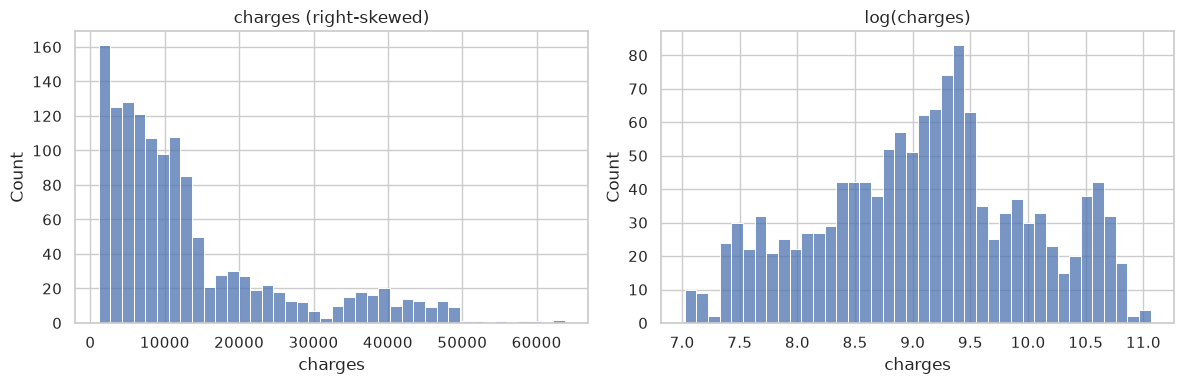

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["charges"], bins=40, ax=axes[0]).set_title("charges (right-skewed)")
sns.histplot(np.log(df["charges"]), bins=40, ax=axes[1]).set_title("log(charges)")
plt.tight_layout(); plt.show()

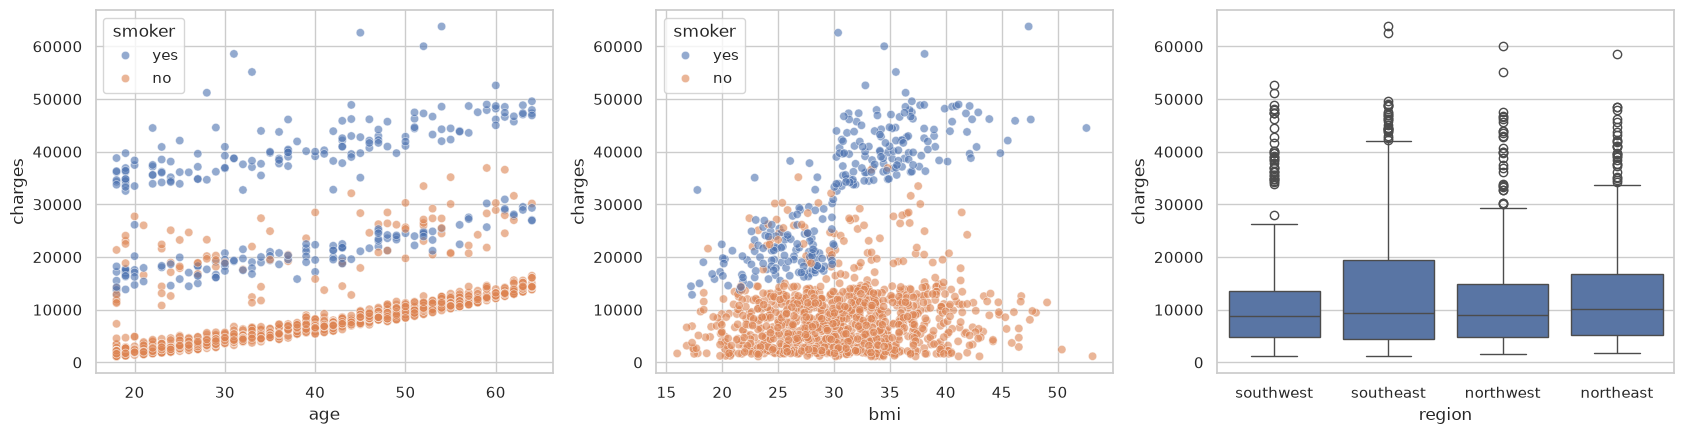

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(data=df, x="age", y="charges", hue="smoker", alpha=.6, ax=axes[0])
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", alpha=.6, ax=axes[1])
sns.boxplot(data=df, x="region", y="charges", ax=axes[2])
plt.tight_layout(); plt.show()

In [6]:
df.groupby("smoker")["charges"].agg(["count","median","mean"]).round(0)

,count,median,mean
smoker,,,
no,1063,7346.0,8441.0
yes,274,34456.0,32050.0


## 3. Feature engineering and encoding
The smoker × BMI scatter suggests an interaction: obese smokers form a separate high-cost cluster. We add `obese` (BMI ≥ 30) and `smoker_obese`, one-hot encode categoricals and scale numerics.

In [7]:
feat = df.copy()
feat["obese"] = (feat["bmi"] >= 30).astype(int)
feat["smoker_obese"] = ((feat["smoker"] == "yes") & (feat["obese"] == 1)).astype(int)
num = ["age","bmi","children","obese","smoker_obese"]; cat = ["sex","smoker","region"]
X, y = feat[num + cat], feat["charges"]
prep = ColumnTransformer([("num", StandardScaler(), num),
                          ("cat", OneHotEncoder(drop="first"), cat)])

## 4. Model comparison — 10-fold cross-validation

In [8]:
models = {
    "Mean baseline": DummyRegressor(),
    "Linear regression": LinearRegression(),
    "Ridge (alpha=1)": Ridge(alpha=1.0),
    "Linear regression, log target": TransformedTargetRegressor(LinearRegression(), func=np.log, inverse_func=np.exp),
    "Random forest": RandomForestRegressor(n_estimators=400, min_samples_leaf=3, random_state=SEED),
    "Gradient boosting": GradientBoostingRegressor(max_depth=3, learning_rate=0.05, n_estimators=300, random_state=SEED),
}
cv = KFold(n_splits=10, shuffle=True, random_state=SEED)
rows = []
for name, m in models.items():
    r = cross_validate(Pipeline([("prep", prep), ("reg", m)]), X, y, cv=cv,
                       scoring=["neg_root_mean_squared_error","neg_mean_absolute_error","r2"])
    rows.append({"model": name, "RMSE": -r["test_neg_root_mean_squared_error"].mean(),
                 "MAE": -r["test_neg_mean_absolute_error"].mean(), "R2": r["test_r2"].mean(),
                 "R2_sd": r["test_r2"].std()})
cv_table = pd.DataFrame(rows).set_index("model").sort_values("RMSE")
cv_table.round({"RMSE":0,"MAE":0,"R2":3,"R2_sd":3})

,RMSE,MAE,R2,R2_sd
model,,,,
Linear regression,4475.0,2473.0,0.859,0.035
Ridge (alpha=1),4475.0,2479.0,0.859,0.035
Gradient boosting,4611.0,2521.0,0.851,0.034
Random forest,4626.0,2587.0,0.850,0.030
"Linear regression, log target",8714.0,4111.0,0.454,0.204
Mean baseline,12078.0,9094.0,-0.003,0.005


## 5. Hold-out check of gradient boosting

hold-out RMSE 4,246 | MAE 2,485 | R2 0.902


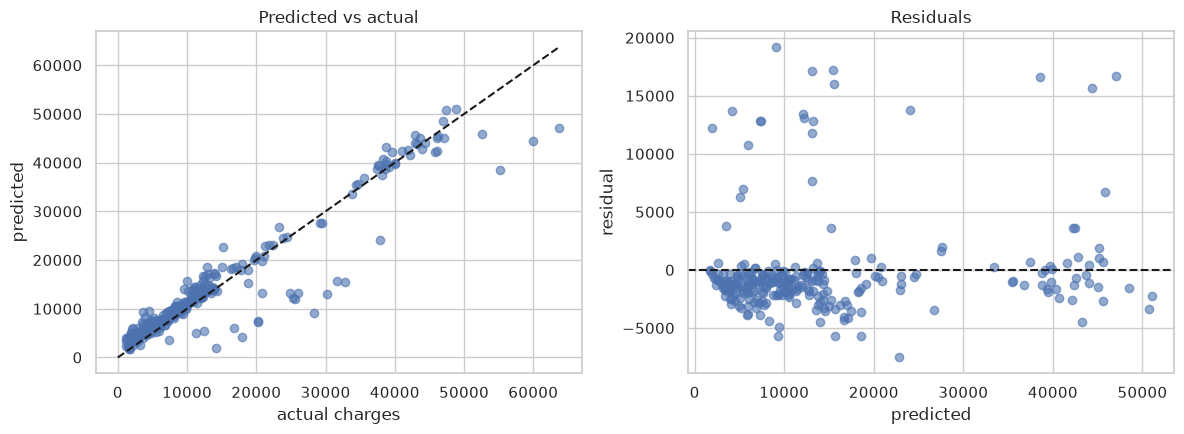

In [9]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)
gb = Pipeline([("prep", prep), ("reg", models["Gradient boosting"])]).fit(X_tr, y_tr)
p = gb.predict(X_te)
print(f"hold-out RMSE {root_mean_squared_error(y_te,p):,.0f} | MAE {mean_absolute_error(y_te,p):,.0f} | R2 {r2_score(y_te,p):.3f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_te, p, alpha=.6); axes[0].plot([0, y.max()], [0, y.max()], "k--")
axes[0].set(xlabel="actual charges", ylabel="predicted", title="Predicted vs actual")
axes[1].scatter(p, y_te - p, alpha=.6); axes[1].axhline(0, color="k", ls="--")
axes[1].set(xlabel="predicted", ylabel="residual", title="Residuals")
plt.tight_layout(); plt.show()

## 6. What drives the cost? Permutation importance

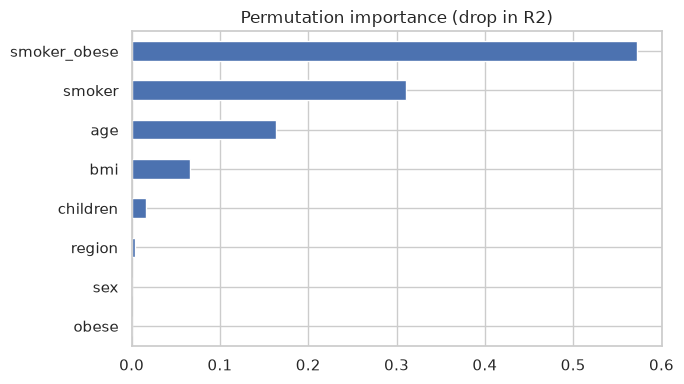

smoker_obese    0.572
smoker          0.311
age             0.163
bmi             0.066
children        0.016
region          0.003
sex             0.000
obese           0.000
dtype: float64

In [10]:
imp = permutation_importance(gb, X_te, y_te, n_repeats=30, random_state=SEED)
importance = pd.Series(imp.importances_mean, index=X.columns).sort_values()
importance.plot.barh(figsize=(7,4), title="Permutation importance (drop in R2)"); plt.tight_layout(); plt.show()
importance.sort_values(ascending=False).round(3)

## 7. Analysis
* Smoking status, especially combined with obesity, and age dominate the predictions; sex and region contribute little.
* With the engineered `smoker_obese` feature, plain linear regression (CV R² 0.859) matched or slightly beat the tree ensembles (0.850–0.851); modelling log(charges) with a linear model did much worse (R² 0.454).
* Large residuals remain for some patients: the dataset has no information on diagnoses or treatments, which limit any model built on these six attributes.
* Learning exercise only; the data are a public teaching dataset, not real insurer pricing.